# Saturation concentration (c_sat)

The **saturation concentration** is the defining number of a phase-separating protein. Below c_sat the protein stays dissolved. Above it, the protein separates into a **dilute phase** (the nucleoplasm) and a **dense phase** (the foci).
A mutation, a binding partner or a drug that changes c_sat changes the protein's **drive to phase separate**:
* **lower c_sat**: phase separation happens at lower concentration, so the drive is **stronger**;
* **higher c_sat**: more protein is needed, so the drive is **weaker**.

This is often the most meaningful LLPS readout, because c_sat is a property of the protein, while foci counts or sizes also depend on expression level and time.

### Every cell is a point on the phase diagram

Cells express different amounts of protein, so a single image set samples many concentrations. Here, for each cell:

| Quantity | Column | Meaning |
|---|---|---|
| **total concentration** c_tot | `nucleus_mean_intensity` | mean intensity of the whole nucleus |
| **dilute phase** c_dil | `nucleoplasm_mean_intensity` | mean intensity outside the foci (and a 2 px ring around them) |
| **protein in foci** | `fraction_signal_in_foci` | foci signal / nuclear signal |
| **foci present** | `n_foci` | whether the cell has phase separated |

All concentrations are in **intensity units**. That's fine for comparing conditions **imaged with identical settings**, but it is not an absolute concentration (see *Limitations*).

### What the theory predicts (single-component phase separation)

For c_tot < c_sat there are no foci, and c_dil = c_tot.
For c_tot > c_sat, foci appear and **c_dil stays at c_sat** (*buffering*): the extra protein goes into the dense phase.
The **lever rule** then gives the fraction of protein in foci:

$$f_\text{foci} \;\approx\; 1 - \frac{c_\text{sat}}{c_\text{tot}} \qquad (c_\text{tot} > c_\text{sat})$$

so it rises from 0 at c_sat towards 1 at high expression.

In cells, buffering is usually **imperfect**. Other molecules co-condense, so the dilute phase still rises slowly above c_sat (Riback *et al.*, *Nature* 2020).
That rise is summarised by the **buffering exponent** β, the log-log slope of c_dil vs. c_tot above c_sat: **β = 0** is perfect buffering, **β = 1** means no buffering at all.

### Three independent estimates

| Method | Data used | c_sat is… | Needs |
|---|---|---|---|
| **1. Onset** | foci yes/no vs. c_tot | c_tot at which half the cells have foci | cells **with and without** foci |
| **2. Dilute-phase buffering** | c_dil vs. c_tot (log-log) | the break where the dilute phase stops following c_tot | a visible break: β clearly < 1 |
| **3. Lever rule** | f_foci vs. c_tot | where the fitted curve 1 − c_sat/c_tot reaches 0 | f_foci rising with c_tot |

**If the methods agree, the estimate is robust.** Each method also reports a **verdict**: the notebook doesn't report a number when the data don't support it.

### Workflow

| Step | Section |
|---|---|
| 1 | Parameters |
| 2 | Load data, design check |
| 3 | Phase-diagram overview: does the data look like phase separation at all? |
| 4–6 | The three methods |
| 7 | Comparison of conditions |
| 8 | Limitations and how to get a better c_sat |
| 9 | Save and report |

In [1]:
%matplotlib inline
from CSAT_utils import *

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

# 1. Parameters

### `data`

This is the same format as `METRICS.ipynb` and `PCA_v2.ipynb`: one entry per condition × biological replicate.
`nucleoplasm_mean_intensity` is taken from `aggregated_data.csv`. For files made with an older `agg.py`, it is read from `summary/summary.csv` in the same folder.

### `OFFSET`: intensity that is not protein

Every method compares **ratios** of intensities (c_sat / c_tot, c_dil / c_tot). A constant offset in the images, such as the camera's dark level or a uniform background, distorts them: it adds to both intensities and pushes every ratio towards 1.
Measure the mean grey value of a region **outside the cells** in a few raw images and enter it here.
It's 0 if the offset was already removed, but **not** if the images were processed with rolling-ball subtraction (see *Limitations*).

### `PRESENCE`: when has a cell phase separated?

Method 1 needs a yes/no per cell. The default is *at least one focus*. If small noise spots are segmented as foci in cells that are clearly diffuse, use a stricter rule, e.g. `area_fraction > 0.005`.

In [2]:
# Root directory where the data is stored
DATA_DIR = "path/to/data"   # folder that holds the condition subfolders (WT/, MGS3/, ...)

data = [
    {"condition": "WT",   "replicate": "1", "path": f"{DATA_DIR}/WT/gmm/aggregated_data.csv"},
    {"condition": "MGS3", "replicate": "1", "path": f"{DATA_DIR}/MGS3/gmm/aggregated_data.csv"},
]

REFERENCE = "WT"
COMPARISONS = "vs_reference"   # "vs_reference" or "all_pairs"
OFFSET = 0                     # grey value outside cells (camera offset / background), subtracted from intensities

def PRESENCE(cells):
    # "this cell has phase separated"
    return cells["n_foci"] >= 1

N_BOOT = 1000                  # bootstrap iterations for the confidence intervals
CONFIDENCE = 0.95
ALPHA = 0.05
SAVE_RESULTS = True
output_dir = Path(DATA_DIR) / "csat"   # tables and figures are saved here

# 2. Load the data and check the design

For c_sat estimates, **the range of expression matters more than the number of cells**. Ideally it spans from well below to well above c_sat, i.e. a 10-fold range or more.
The table below the design shows the range per condition.

In [3]:
df = load_conditions(data)
if OFFSET:
    df = subtract_offset(df, OFFSET)
df = df.dropna(subset=[TOTAL, DILUTE])
TEST_LEVEL = check_design(df)
palette = condition_palette(list(df["condition"].cat.categories))
display(design_table(df))

rng_table = df.groupby("condition", observed=True)[TOTAL].agg(["min", "median", "max"])
rng_table["fold_range"] = rng_table["max"] / rng_table["min"]
rng_table["cells_with_foci_%"] = df.groupby("condition", observed=True).apply(
    lambda g: 100 * PRESENCE(g).mean(), include_groups=False)
rng_table.round(1)

nucleoplasm_mean_intensity read from summary/summary.csv next to each aggregated_data.csv
  Replicate-level tests are impossible. Only cell-level tests are
  computed: their p-values treat every cell as independent and
  overstate significance. Use them as descriptive only.


,rep 1,n_replicates,n_cells,cells_without_foci
condition,,,,
WT,36,1,36,0
MGS3,26,1,26,0


,min,median,max,fold_range,cells_with_foci_%
condition,,,,,
WT,33.4,115.9,1295.8,38.8,100.0
MGS3,88.1,321.6,1507.9,17.1,100.0


# 3. Phase-diagram overview

Each dot is a cell, positioned by its total concentration (x, log scale). Filled dots are cells with foci; hollow dots are cells without.

What phase separation with a c_sat looks like:

| Panel | Expected |
|---|---|
| **Dilute phase** | on the dashed line (dilute = total) at low expression, then **bending away and levelling off** above c_sat |
| **Protein in foci** | 0 at low expression, **rising** above c_sat |
| **Area in foci** | rising above c_sat (the dense-phase volume grows) |
| **Partition coefficient** | roughly constant (both phases at fixed concentrations) |

**If instead the dilute phase runs parallel to the dashed line over the whole range and the protein in foci stays flat, the cells look like scaled copies of each other.** No saturation is visible, and no method below can give a meaningful c_sat. Section 8 lists the usual causes.

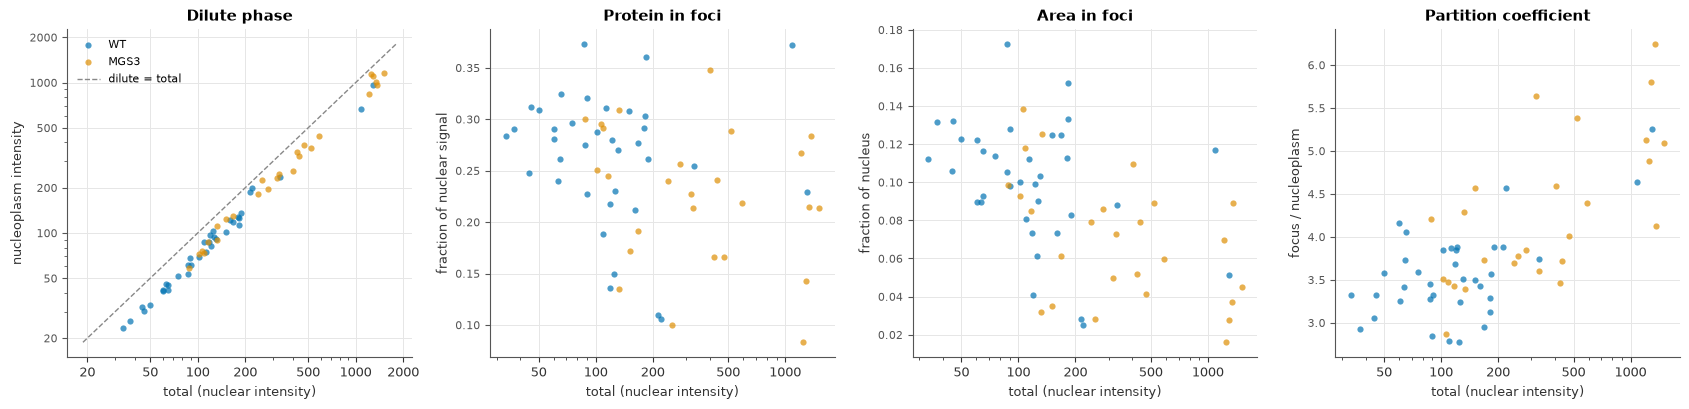

In [4]:
fig = plot_phase_overview(df, palette, PRESENCE)
if SAVE_RESULTS:
    output_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_dir / "phase_overview.png", dpi=300, bbox_inches="tight")
plt.show()

# 4–6. The three estimates

All estimates are computed together, each with a 95 % **hierarchical-bootstrap** CI that resamples replicates, then cells, so it includes the variability between experiments.

| Column | Meaning |
|---|---|
| `estimate` | c_sat in intensity units |
| `ci_low`, `ci_high` | bootstrap confidence interval |
| `beta`, `beta_ci_*` | buffering exponent (method 2): 0 = perfect buffering, 1 = none |
| `delta_bic` | method 2: how much better the segmented model fits than a straight line. **> 2** positive evidence for a break, **> 6** strong, **< 2** no evidence |
| `rho` | method 3: Spearman correlation of protein-in-foci with total. The lever rule needs it clearly **positive** |
| `verdict` | **ok**, *extrapolated* (c_sat lies outside the measured range, so treat it with caution), or why the estimate isn't reliable |

In [5]:
table, boots = estimate_all(df, PRESENCE, n_boot=N_BOOT, confidence=CONFIDENCE)
table[["condition", "method", "n_cells", "estimate", "ci_low", "ci_high", "beta", "beta_ci_low",
       "beta_ci_high", "delta_bic", "rho", "verdict"]].round(3)

,condition,method,n_cells,estimate,ci_low,ci_high,beta,beta_ci_low,beta_ci_high,delta_bic,rho,verdict
0,WT,onset,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,not estimable: 0 cells without foci (needs >= 5 with and without)
1,WT,buffering,36,220.084,45.372,329.660,0.971,0.881,2.320,-3.427,NaN,"no buffering (beta = 0.97): dilute phase rises with total, c_sat not identifiable"
2,WT,lever,36,0.033,0.033,1.448,NaN,NaN,NaN,NaN,-0.237,"lever rule not followed (signal in foci does not rise with total, rho = -0.24): c_sat not identifiable"
3,MGS3,onset,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,not estimable: 0 cells without foci (needs >= 5 with and without)
4,MGS3,buffering,26,108.902,101.907,1341.753,1.023,-1.560,1.465,-3.399,NaN,no clear break (BIC prefers a straight line): unreliable
5,MGS3,lever,26,0.088,0.088,15.011,NaN,NaN,NaN,NaN,-0.303,"lever rule not followed (signal in foci does not rise with total, rho = -0.30): c_sat not identifiable"


### Method 1: Onset of phase separation

Cells are binned by expression. For each bin, the plot shows the **fraction of cells with foci**, plus a logistic fit. c_sat is where the fitted curve crosses 50 % (dotted line).
The steepness of the curve reflects cell-to-cell variability. A shallow curve means cells with the same expression differ in whether they phase separate, e.g. because of the cell cycle or cofactors.

This method needs cells **on both sides** of the threshold. If every cell has foci, as often happens with sensitive segmentation, it isn't estimable: include more low-expressing cells, or use a stricter `PRESENCE`.

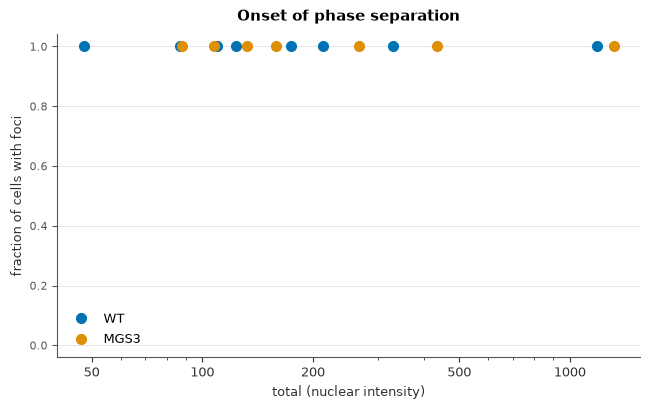

In [6]:
fig = plot_onset(df, palette, PRESENCE)
if SAVE_RESULTS:
    fig.savefig(output_dir / "onset.png", dpi=300, bbox_inches="tight")
plt.show()

### Method 2: Dilute-phase buffering

These are log-log plots of dilute vs. total, one per condition. Two models are fitted:
* the **segmented** model (coloured line): slope 1 below the break, slope β above it. **The break is c_sat** (dotted line, shown only when the verdict is *ok*);
* the **straight line** (dash-dot): a single slope everywhere, i.e. no saturation.

How to read it:
* **β ≈ 0–0.5 with a clear break** (`delta_bic` > 2) shows buffering, and c_sat is well defined;
* **β ≈ 1, and the two lines coincide**: the dilute phase rises in proportion to the total. There's no buffering, and c_sat can't be determined from these cells.

The vertical gap between the dots and the dashed line at low expression reflects that `nucleoplasm_mean_intensity` excludes the foci and their surroundings. The model absorbs it as a constant factor.

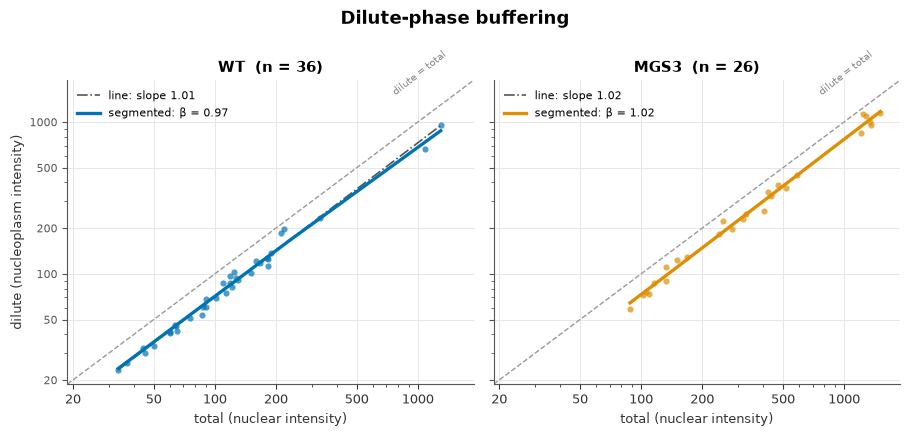

In [7]:
fig = plot_buffering(df, palette, table)
if SAVE_RESULTS:
    fig.savefig(output_dir / "buffering.png", dpi=300, bbox_inches="tight")
plt.show()

### Method 3: Lever rule

The plot shows the fraction of nuclear protein in foci vs. total, with the fitted lever-rule curve 1 − c_sat/c_tot (scaled by a factor A that absorbs blur and segmentation).
c_sat is where the curve meets 0 (dotted line). **Solid line**: the fit is reliable. **Dashed line**: the data don't follow the lever rule.

The lever rule is the most data-efficient method: it uses every cell above c_sat, even when no cell lies below c_sat. But it assumes a fixed dilute concentration (β ≈ 0), so check method 2.

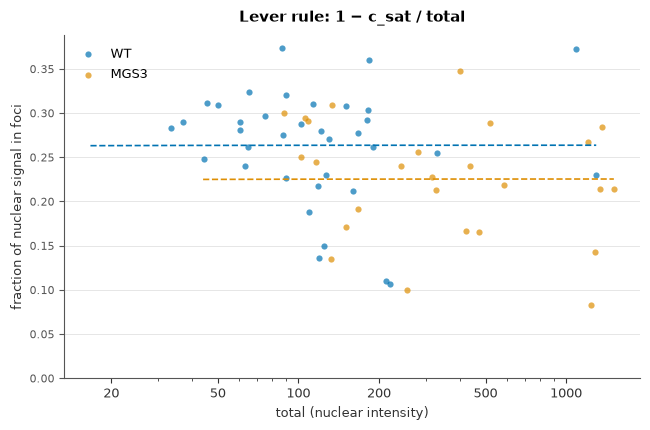

In [8]:
fig = plot_lever(df, palette, table)
if SAVE_RESULTS:
    fig.savefig(output_dir / "lever_rule.png", dpi=300, bbox_inches="tight")
plt.show()

# 7. Comparison of conditions

### All estimates at a glance

Filled dots are reliable estimates; hollow dots are estimates whose verdict is not *ok*. Look for **agreement between methods**: a mutant whose c_sat is lower by all methods with available data is convincing.

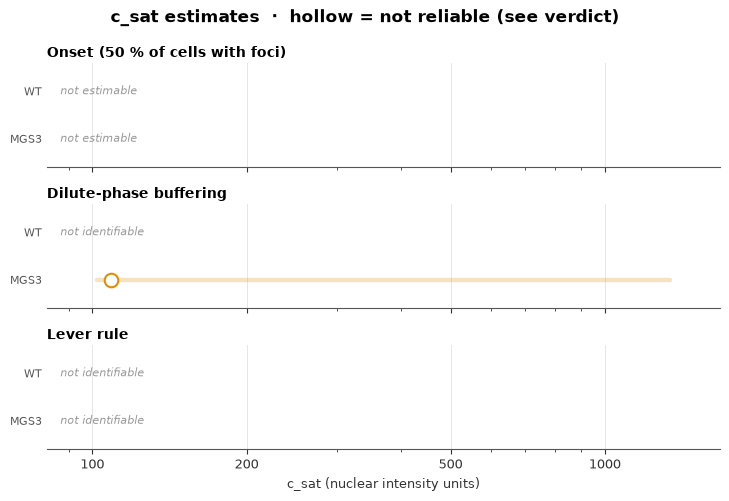

In [9]:
fig = plot_estimates(table, palette)
if SAVE_RESULTS:
    fig.savefig(output_dir / "csat_estimates.png", dpi=300, bbox_inches="tight")
plt.show()

### Ratio vs. the reference

`ratio` = c_sat(condition) / c_sat(reference) for each method, with a bootstrap CI.
A **ratio < 1** means a lower c_sat, i.e. a stronger drive to phase separate. A ratio whose CI excludes 1 is a difference beyond the resampling uncertainty.
`p_bootstrap` is the two-sided bootstrap p-value, and `q` its FDR correction. Only estimates with a usable verdict are compared.

With **one replicate per condition**, these CIs reflect cell-to-cell variability only, not reproducibility between experiments.

In [10]:
ratios = compare_to_reference(table, boots, REFERENCE, confidence=CONFIDENCE)
if ratios.empty:
    print("No method gave a usable c_sat for the reference and another condition: "
          "nothing to compare (see the verdicts above and section 8).")
ratios.round(3)

No method gave a usable c_sat for the reference and another condition: nothing to compare (see the verdicts above and section 8).


,method,condition,baseline,ratio,ci_low,ci_high,p_bootstrap


### Replicate-level test

With **≥ 2 replicates per condition** (at least 20 cells each), c_sat and β are estimated **in each replicate separately**. Conditions are then compared with Welch's *t*-test on log₁₀ c_sat (β on its own scale), with *n* = the number of replicates.
This is the test to base conclusions on, as in the other notebooks.

In [11]:
rep_est = replicate_estimates(df, PRESENCE)
pairs = comparison_pairs(df["condition"].cat.categories, reference=REFERENCE, mode=COMPARISONS)
rep_tests = replicate_tests(rep_est, pairs) if TEST_LEVEL == "replicates" else pd.DataFrame()
if rep_tests.empty:
    print("Replicate-level test not possible: needs >= 2 replicates (>= 20 cells each) per condition.")
display(rep_est.round(3))
rep_tests.round(4)

Replicate-level test not possible: needs >= 2 replicates (>= 20 cells each) per condition.


,condition,replicate,n_cells,buffering,beta,lever,onset
0,WT,1,36,220.084,0.971,0.033,NaN
1,MGS3,1,26,108.902,1.023,0.088,NaN


""


# 8. Limitations, and how to get a better c_sat

**Intensity units.** The c_sat values are mean grey values. They compare conditions **only if all were imaged with the same microscope, objective, laser power, gain and pixel size**.
To convert them to µM, image a dilution series of purified fluorescent protein, or of a dye with a known concentration, under the same settings.

**Why the methods can fail even when the protein does phase separate:**

| Cause | Effect | Fix |
|---|---|---|
| **Rolling-ball background subtraction before analysis** (e.g. file names ending in `_bg_subtracted`) | removes part of the diffuse nucleoplasm, so c_dil and c_tot are distorted in a size-dependent way | measure on **raw** images: set `rolling_ball_radius = 0` and use images without pre-subtraction; enter the camera offset as `OFFSET` |
| **Camera offset / background not subtracted** | ratios are pulled towards 1, β towards 1 | measure the grey value outside cells and set `OFFSET` |
| **Blur from foci** spreads dense-phase light into the nucleoplasm | c_dil is overestimated, especially in cells with many foci | Airyscan / deconvolved images; widen `NUCLEOPLASM_RING_PX` in `outsu.py` / `gmm.py` |
| **All cells above c_sat** | onset not estimable; the buffering break is extrapolated | include low-expressing cells: lower plasmid amount, inducible expression, or simply more cells |
| **Saturated pixels** in bright cells | c_tot and f_foci are underestimated at high expression | check for saturation; use a lower gain for high expressers |
| **Segmentation that adapts to each image** (Otsu / GMM thresholds per image) | dim, nearly diffuse cells still get "foci" | a stricter `PRESENCE` rule, or a fixed threshold |
| **Multi-component condensates** | the dilute phase genuinely keeps rising (β > 0): c_sat is not a single number | report β; compare conditions by β as well |

**Expression level vs. c_sat.** If two conditions have different expression ranges, compare them over the **shared** range. `METRICS.ipynb` section 7 does this for the foci metrics.

# 9. Save and report

In [ ]:
if SAVE_RESULTS:
    output_dir.mkdir(parents=True, exist_ok=True)
    table.to_csv(output_dir / "csat_estimates.csv", index=False)
    ratios.to_csv(output_dir / "csat_ratios.csv", index=False)
    rep_est.to_csv(output_dir / "csat_per_replicate.csv", index=False)
    if not rep_tests.empty:
        rep_tests.to_csv(output_dir / "csat_replicate_tests.csv", index=False)
    print(f"Saved to {output_dir}")

### Reporting checklist

* **Concentration measure:** *"mean nuclear intensity as total concentration; mean nucleoplasm intensity, excluding foci and a 2 px ring, as dilute-phase concentration; camera offset of X grey values subtracted; identical imaging settings for all conditions."*
* **Method(s):** which methods gave usable estimates, and whether they agree.
* **The numbers:** c_sat with its 95 % CI per condition, and the ratio vs. the control with its CI, e.g. *"c_sat of MGS3 was 0.6× that of WT (95 % CI 0.5–0.7)"*.
* **Buffering:** β with its CI. It shows how ideal the phase separation is.
* **Replicates:** *n* experiments, and the replicate-level test.
* **The expression range:** min–max per condition, and the share of cells with foci.

Example sentence:
> *Cells phase separated above a nuclear intensity of 104 a.u. (WT; onset, 95 % CI 98–106), consistent with the lever-rule estimate (104 a.u.) and the break of the dilute phase (106 a.u.; buffering exponent β = 0.13). MGS3 lowered c_sat to 0.60× WT (95 % CI 0.58–0.63; all three methods; n = 3 experiments, p = 0.002), indicating a stronger drive to phase separate.*